## **Setup:**

In [3]:
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS  # stop-word list only

np.random.seed(0)  # reproducible runs

### Helper functions:

In [4]:
def euclidean_distance(a, b):
    """Computes the Euclidean (L2) distance of two vectors: ||a - b||"""
    return np.linalg.norm(a - b, axis=-1)


def assign(X, centers):
    """Returns labels and Euclidean distance from each point to its assigned center: phi_C(x) = argmin_c d(x, c)"""
    D = euclidean_distance(X[:, None, :], centers[None, :, :])
    phi = D.argmin(axis=1)
    return phi, D[np.arange(len(X)), phi]

def cost_2(S, X):
    """Returns the cost of clustering X into C: Cost_2(S, X) = (1 / |X|) sum_x ||x - phi_S(x)||^2"""
    _, d = assign(X, S) 
    return (d ** 2).mean()

### Algorithm functions:

In [5]:
def kmeans_plus_plus(X, k):
    """kmeans++ seeding: first center chosen uniformly at random, each next center chosen
    with probability proportional to its squared distance to the nearest chosen center"""
    centers = [X[np.random.randint(len(X))]]
    d2 = ((X - centers[0]) ** 2).sum(axis=1)

    for i in range(1, k):
        new_center = X[np.random.choice(len(X), p=d2 / d2.sum())]
        centers.append(new_center)
        d2 = np.minimum(d2, ((X - new_center) ** 2).sum(axis=1))

    centers = np.array(centers)
    phi, _ = assign(X, centers)
    return centers, phi

def lloyds(X, centers):
    """Lloyd's algorithm: assign, re-average, repeat until unchanged"""
    while True:
        phi = ((centers ** 2).sum(axis=1) - 2 * X @ centers.T).argmin(axis=1)

        # If a cluster ends up empty, keep its old center instead of averaging nothing (NaN)
        new_centers = np.array([X[phi == i].mean(axis=0) if np.any(phi == i) else centers[i]
                                for i in range(len(centers))])

        if np.array_equal(new_centers, centers):
            break
        else:
            centers = new_centers

    return centers, phi

def kmeans(X, k, R):
    """Runs kmeans with Lloyd's algorithm (using kmeans++ initialization), keeps the lowest-cost of R runs"""
    runs = []

    for _ in range(R):
        centers, phi = kmeans_plus_plus(X, k)
        centers, phi = lloyds(X, centers)
        runs.append((centers, phi))

    return min(runs, key=lambda run: cost_2(run[0], X))

### Cost evaluation functions:

In [6]:
def elbow_method(X):
    """Score cost of clustering X into C: Cost_2(S, X) = (1 / |X|) sum_x ||x - phi_S(x)||^2"""
    costs = []

    for k in range(2, 11):
        c, _ = kmeans(X, k, 10)
        costs.append(cost_2(c, X))

    return costs

def silhouette_score(X, phi):
    """Returns the silhouette score of clustering X: sil(S, X) = (1 / |X|) sum_x (b(x) - a(x)) / max(a(x), b(x))"""
    scores = np.zeros(len(X))
    clusters = np.unique(phi)

    # All pairwise distances at once: ||x - y||^2 = ||x||^2 + ||y||^2 - 2<x, y>
    squared_norms = (X ** 2).sum(axis=1)
    D = np.sqrt(np.maximum(squared_norms[:, None] + squared_norms - 2 * X @ X.T, 0))

    for j in range(len(X)):
        same_cluster = phi == phi[j]

        if same_cluster.sum() == 1:
            continue

        a = D[j][same_cluster].sum() / (same_cluster.sum() - 1)
        b = min(D[j][phi == i].mean() for i in clusters if i != phi[j])
        scores[j] = (b - a) / max(a, b)

    return scores.mean()

## **Build feature matrices:**

### Build matrix 1: reviewers

In [7]:
# Load reviewer_features.csv and set reviewer aside
reviewer_features = pd.read_csv('data/reviewer_features.csv')
reviewers = reviewer_features['reviewer']

# Behavior-only features. avg_rating is left OUT: it is the outcome we want to explain,
# so we compare ratings across clusters afterwards instead of clustering on them.
feature_cols = ['reported_reviews', 'followers', 'avg_review_length', 'avg_pictures']
X = reviewer_features[feature_cols].to_numpy(dtype=float)

# Counts are heavily right-skewed (followers: median 4, max 13,410), so log-transform before standardizing
X = np.log1p(X)
X = (X - X.mean(axis=0)) / X.std(axis=0)

### Build matrix 2: review text
*Stop words removed, very short reviews dropped, TF-IDF weighting*

In [8]:
# Load reviews and drop missing text
restaurant_reviews_cleaned = pd.read_csv('data/restaurant_reviews_cleaned.csv').dropna(subset=['review'])

# Split each review into lowercase letter-only tokens, removing stop words ("the", "and", "was", ...)
tokens = restaurant_reviews_cleaned['review'].str.lower().str.findall(r'[a-z]+')
tokens = tokens.apply(lambda words: [w for w in words if w not in ENGLISH_STOP_WORDS and len(w) > 1])

# Drop very short reviews (< 5 content words) -- they formed their own cluster purely by length
long_enough = tokens.str.len() >= 5
tokens = tokens[long_enough]
restaurant_reviews_cleaned = restaurant_reviews_cleaned[long_enough]

# Keep words that appear in at least 5 reviews
review_counts = Counter(word for words in tokens for word in set(words))
vocabulary = [word for word, count in review_counts.items() if count >= 5]
word_to_column = {word: j for j, word in enumerate(vocabulary)}

# Fill in the word counts
word_counts = np.zeros((len(tokens), len(vocabulary)), dtype=np.float32)
for i, words in enumerate(tokens):
    for word in words:
        if word in word_to_column:
            word_counts[i, word_to_column[word]] += 1

# Remove reviews with no words left
has_words = word_counts.sum(axis=1) > 0
word_counts = word_counts[has_words]
review_labels = restaurant_reviews_cleaned[has_words]

# TF-IDF: down-weight words that appear in many reviews. idf(w) = log(N / df(w))
document_freq = (word_counts > 0).sum(axis=0)
idf = np.log(len(word_counts) / document_freq).astype(np.float32)
tfidf = word_counts * idf

# Normalize each row to length 1
X_text = tfidf / np.linalg.norm(tfidf, axis=1, keepdims=True)
print("Text matrix:", X_text.shape)

Text matrix: (8333, 3927)


## **Run algorithms and evaluations on matrices:**

In [9]:
def run_k_search(X, R):
    ks = list(range(2, 11))
    costs = []
    silhouettes = []
    labels = {}

    for k in ks:
        centers, phi = kmeans(X, k, R)
        costs.append(cost_2(centers, X))
        silhouettes.append(silhouette_score(X, phi))
        labels[k] = phi

        print(f"k= {k}:\n\tCost_2: {costs[-1]:.4f}\n\tSilhouette: {silhouettes[-1]:.4f}\n\tLabels: {np.bincount(phi)}")

    return ks, costs, silhouettes, labels

def plot_k_search(ks, costs, silhouettes, title):
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.plot(ks, costs, marker='o')
    ax1.set(title=f'{title}: Elbow', xlabel='k', ylabel='Cost_2')
    ax2.plot(ks, silhouettes, marker='o')
    ax2.set(title=f'{title}: Silhouette', xlabel='k', ylabel='Average silhouette')
    plt.show()

In [ ]:
def pca_2d(A):
    """PCA: SVD of centered A"""
    A_tilde = A - A.mean(axis=0)
    _, S, Vt = np.linalg.svd(A_tilde, full_matrices=False) 

    return A_tilde @ Vt[:2].T, S[:2] ** 2 / (S ** 2).sum()

def plot_best_clusters(X, ks, silhouettes, labels, title):
    best_k = ks[np.argmax(silhouettes)]
    phi = labels[best_k]
    coords, variance = pca_2d(X)
    _, ax = plt.subplots(figsize=(8, 6))

    for i in np.unique(phi):
        in_cluster = phi == i
        ax.scatter(coords[in_cluster, 0], coords[in_cluster, 1], s=8, alpha=0.4,
                   label=f'Cluster {i} (n={in_cluster.sum()})')
        
    ax.set(title=f'{title}: best k = {best_k} (silhouette {max(silhouettes):.4f})',
           xlabel=f'PC1 ({variance[0]:.0%} of variance)',
           ylabel=f'PC2 ({variance[1]:.0%} of variance)')
    ax.legend(markerscale=2)
    
    plt.show()

Reviewers:



k= 2:
	Cost_2: 2.2955
	Silhouette: 0.4531
	Labels: [1903 5539]
k= 3:
	Cost_2: 1.6952
	Silhouette: 0.3873
	Labels: [1625 1426 4391]
k= 4:
	Cost_2: 1.2232
	Silhouette: 0.4006
	Labels: [1408 3726  707 1601]
k= 5:
	Cost_2: 1.0369
	Silhouette: 0.3629
	Labels: [1377  664  836 2736 1829]
k= 6:
	Cost_2: 0.8907
	Silhouette: 0.3758
	Labels: [ 805 1376 2622  460 1653  526]
k= 7:
	Cost_2: 0.8149
	Silhouette: 0.3690
	Labels: [ 675 2545  455  506 1355  914  992]
k= 8:
	Cost_2: 0.7470
	Silhouette: 0.3678
	Labels: [ 929 1357 2374  228  932  453  699  470]
k= 9:
	Cost_2: 0.6970
	Silhouette: 0.3393
	Labels: [2006  227  799  444  386 1339  881  450  910]
k= 10:
	Cost_2: 0.6603
	Silhouette: 0.3072
	Labels: [ 443 1929  377  449  881  833  649  870  784  227]


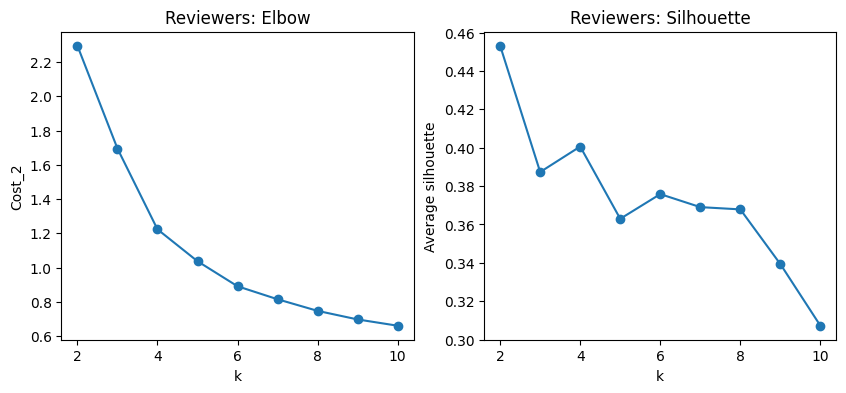

In [ ]:
print("Reviewers:\n")
ks, costs_reviewers, silhouettes_reviewers, labels_reviewers = run_k_search(X, 10)
plot_k_search(ks, costs_reviewers, silhouettes_reviewers, 'Reviewers')
plot_best_clusters(X, ks, silhouettes_reviewers, labels_reviewers, 'Reviewers')   

In [ ]:
print("Review text:\n")
ks, costs_text, silhouettes_text, labels_text = run_k_search(X_text, 3)
plot_k_search(ks, costs_text, silhouettes_text, 'Review text')

Review text:



## **Inspect clusters:**

In [ ]:
def profile_reviewers(k):
    """Median behavior per reviewer cluster, plus the rating stats we did NOT cluster on"""
    df = reviewer_features.assign(cluster=labels_reviewers[k])
    table = df.groupby('cluster')[feature_cols].median().round(1)
    table['n'] = df['cluster'].value_counts().sort_index()
    table['mean_rating'] = df.groupby('cluster')['avg_rating'].mean().round(2)
    table['rating_std'] = df.groupby('cluster')['avg_rating'].std().round(2)
    return table.sort_values('n', ascending=False)

def profile_text(k, top=10):
    """Top TF-IDF terms per text cluster, plus size, average rating and length"""
    phi = labels_text[k]
    rows = []
    for c in range(k):
        center = X_text[phi == c].mean(axis=0)
        in_c = review_labels[phi == c]
        rows.append({'cluster': c, 'n': int((phi == c).sum()),
                     'mean_rating': round(in_c['rating'].mean(), 2),
                     'avg_length': round(in_c['review_length'].mean(), 1),
                     'top_terms': ', '.join(vocabulary[j] for j in np.argsort(-center)[:top])})
    return pd.DataFrame(rows).set_index('cluster')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 200)

In [ ]:
best_k_reviewers = ks[int(np.argmax(silhouettes_reviewers[1:])) + 1]  # best silhouette for k >= 3
print("Reviewer clusters, k =", best_k_reviewers)
profile_reviewers(best_k_reviewers)

NameError: name 'ks' is not defined

In [ ]:
best_k_text = ks[int(np.argmax(silhouettes_text))]
print("Text clusters, k =", best_k_text)
profile_text(best_k_text)
plot_best_clusters(X_text, ks, silhouettes_text, labels_text, 'Review text') 

Text clusters, k = 10


,n,mean_rating,avg_length,top_terms
cluster,,,,
0,482,3.52,66.7,"paneer, paratha, butter, dal, punjabi, north, ordered, masala, roti, naan"
1,1069,1.60,54.6,"worst, bad, order, delivery, restaurant, zomato, don, time, food, experience"
2,2511,3.67,61.0,"good, place, food, taste, ambience, service, try, best, like, just"
3,635,3.56,82.6,"veg, buffet, starters, non, main, course, good, lunch, spread, team"
4,931,3.40,85.9,"chicken, burger, rice, shawarma, ordered, fried, noodles, taste, good, mandi"
5,501,3.27,48.9,"biryani, chicken, taste, ordered, good, mutton, quantity, rice, restaurant, spicy"
6,357,3.84,59.1,"cream, ice, cake, chocolate, momos, cakes, brownies, velvet, cupcakes, red"
7,1082,4.65,41.6,"great, awesome, place, amazing, visit, service, ambience, good, food, friends"
8,261,4.82,32.8,"excellent, service, food, great, good, visit, nice, ambience, experience, time"
